# T16c: searchable range P_max = R/2

Companion notebook to `README.md` in this folder. Running top-to-bottom regenerates every figure in `figures/` from the saved results in `data/` (or the referenced `runs/` directory).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-22_t16c-searchable-range"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


## Load results
Scorecard outputs live in `runs/t16c/{before,after,mvf025}/<run>/` (gitignored; regenerate with the README's Reproduce commands). The analysis code is in `analysis.py`, `mechanisms.py`, `examples.py` next to this notebook; this notebook calls them and shows the outputs.

In [2]:
import os
HERE = REPO / 'reports' / '2026-10-22_t16c-searchable-range'
os.chdir(HERE); sys.path.insert(0, str(HERE))
from IPython.display import Image, display
import warnings; warnings.simplefilter('ignore')
import analysis as an, mechanisms as mech

## Bit-identity and runtime
Every before/after pair: 0 changed stars and identical in-reach candidate rows.

In [3]:
an.main()
display(pd.read_csv('data/bit_identity_summary.csv')[['run','n_stars','n_with_beyond','n_beyond_cands','n_cands_before','n_changed','inreach_candidates_identical']])
print(open('data/check_goals_dm_full.txt').read().split('Regression guard')[1])

                 run  n_stars  n_with_beyond  n_beyond_cands  n_cands_before  n_cands_after  n_changed  n_changed_without_beyond  inreach_candidates_identical  fit_s_median_before  fit_s_median_after  fit_s_total_before  fit_s_total_after  star_s_median_before  star_s_median_after
0            dm_full     1000            487            1261           24129          22868          0                         0                          True             2.247632            2.066507         2421.316927        2103.246776              3.959369             3.721292
1        dm_assigned     1000            536            1247           21122          19875          0                         0                          True             1.344738            1.300295         1398.362682        1364.738449              2.135275             2.058498
2         syn_single      200             25              49            3436           3387          0                         0                          

,run,n_stars,n_with_beyond,n_beyond_cands,n_cands_before,n_changed,inreach_candidates_identical
0,dm_full,1000,487,1261,24129,0,True
1,dm_assigned,1000,536,1247,21122,0,True
2,syn_single,200,25,49,3436,0,True
3,syn_consecutive-2,200,28,70,3719,0,True
4,syn_gapped-2,200,169,273,3460,0,True
5,syn_3-5,200,101,214,3725,0,True
6,syn_6-12,200,113,234,4097,0,True


 (fail if a metric drops by more than its limit):
   base     new   delta  limit  metric
  0.248   0.248  +0.000  0.020  final.overall.success
  0.233   0.233  +0.000  0.060  final.by_bin.1-3d.success
  0.363   0.363  +0.000  0.060  final.by_bin.10-30d.success
  0.298   0.298  +0.000  0.060  final.by_bin.3-10d.success
  0.169   0.169  +0.000  0.060  final.by_bin.<1d.success
  0.210   0.210  +0.000  0.060  final.by_bin.>30d.success
  0.971   0.971  +0.000  0.060  union_recall.by_bin.1-3d
  0.988   0.988  +0.000  0.060  union_recall.by_bin.10-30d
  0.965   0.965  +0.000  0.060  union_recall.by_bin.3-10d
  0.442   0.442  +0.000  0.060  union_recall.by_bin.<1d
  0.917   0.917  +0.000  0.060  union_recall.by_bin.>30d

OVERALL: PASS



Paired fit timing (`profile_fit.py 8`, saved): `max_period=None` vs `'auto'` on identical inputs.

In [4]:
d = pd.read_csv('data/profile_fit.csv'); d['ratio'] = d.fit_s_after / d.fit_s_before
display(d.groupby('coverage_class').agg(n=('ratio','size'), n_beyond=('n_beyond','mean'), fit_before=('fit_s_before','median'), fit_after=('fit_s_after','median'), sum_b=('fit_s_before','sum'), sum_a=('fit_s_after','sum')).assign(total_ratio=lambda t: t.sum_a / t.sum_b).round(3))
print('overall ratio', round(d.fit_s_after.sum() / d.fit_s_before.sum(), 3))

,n,n_beyond,fit_before,fit_after,sum_b,sum_a,total_ratio
coverage_class,,,,,,,
consecutive-2,8,1.875,1.615,1.548,13.573,13.045,0.961
consecutive-3-5,8,1.625,1.919,2.100,16.299,16.529,1.014
full,8,1.375,2.330,2.249,18.209,17.539,0.963
gapped-2,8,3.750,1.094,0.960,9.958,8.249,0.828
single,8,3.000,1.609,1.658,13.018,13.452,1.033


overall ratio 0.968


## R/2 validation per coverage class
Synthetic coverage draws, then dev_medium assigned and full-year. Success is 0 past the dotted R/2 line in every class.

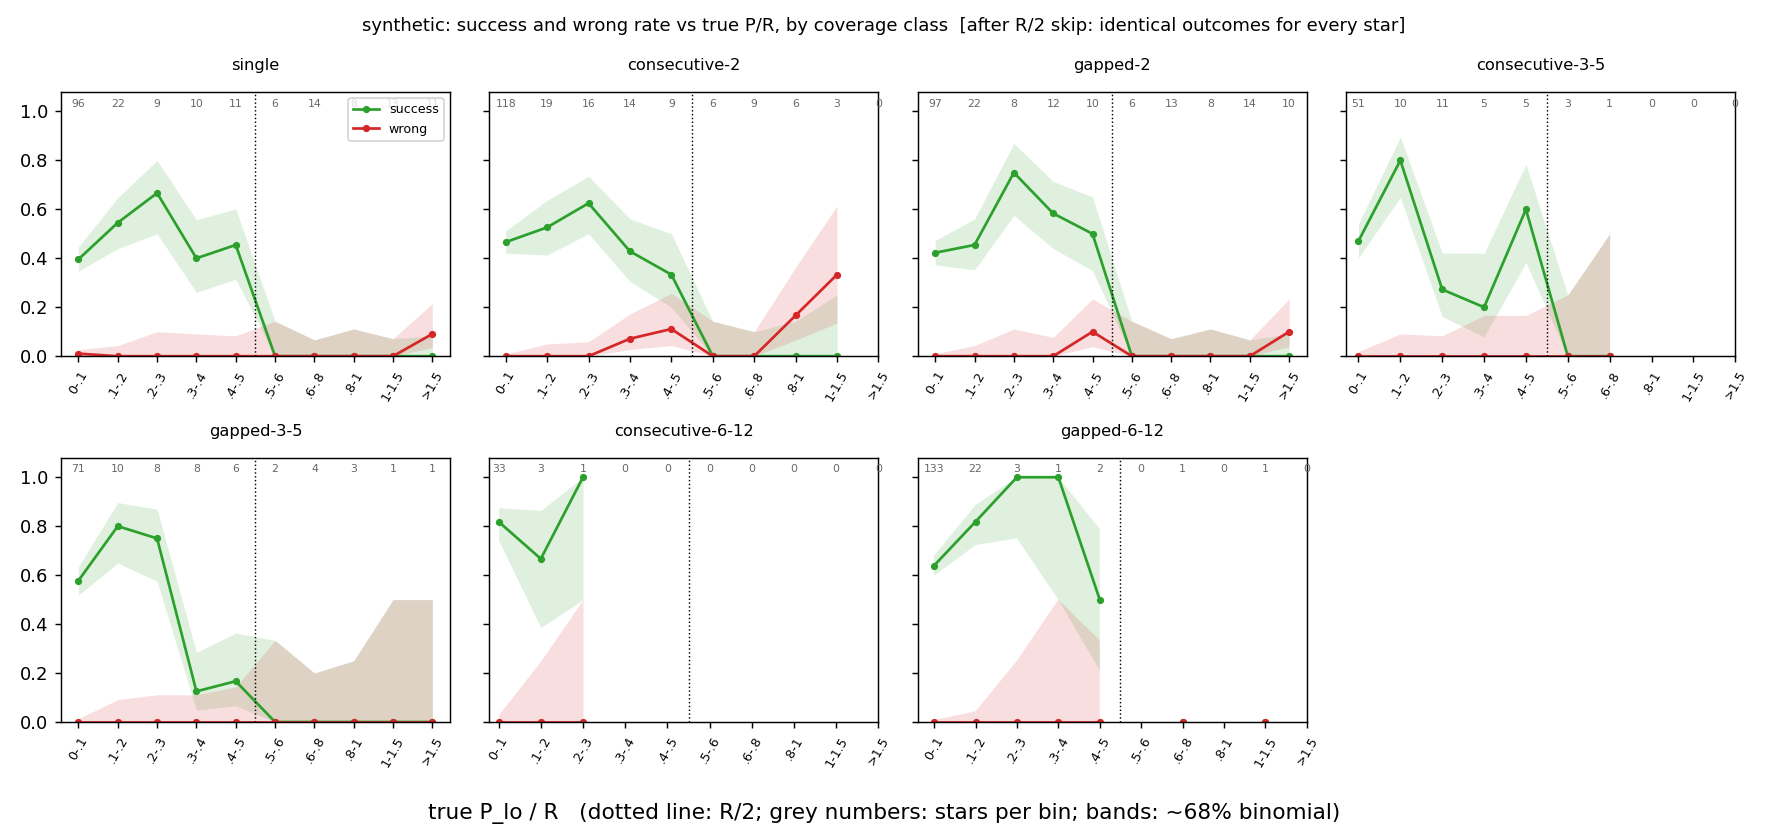

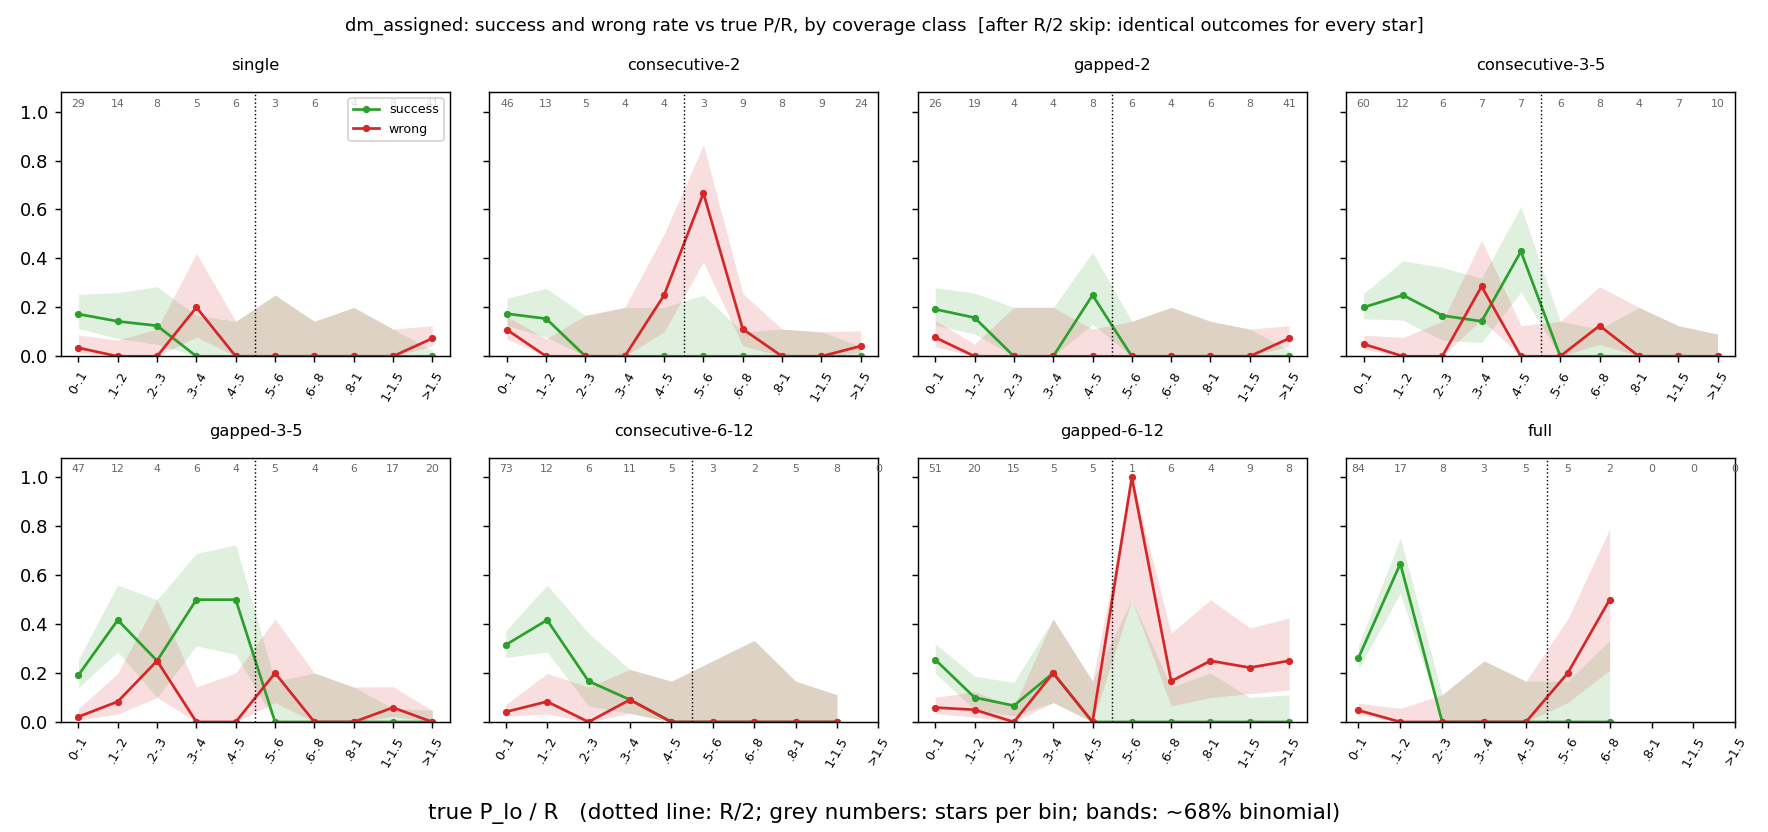

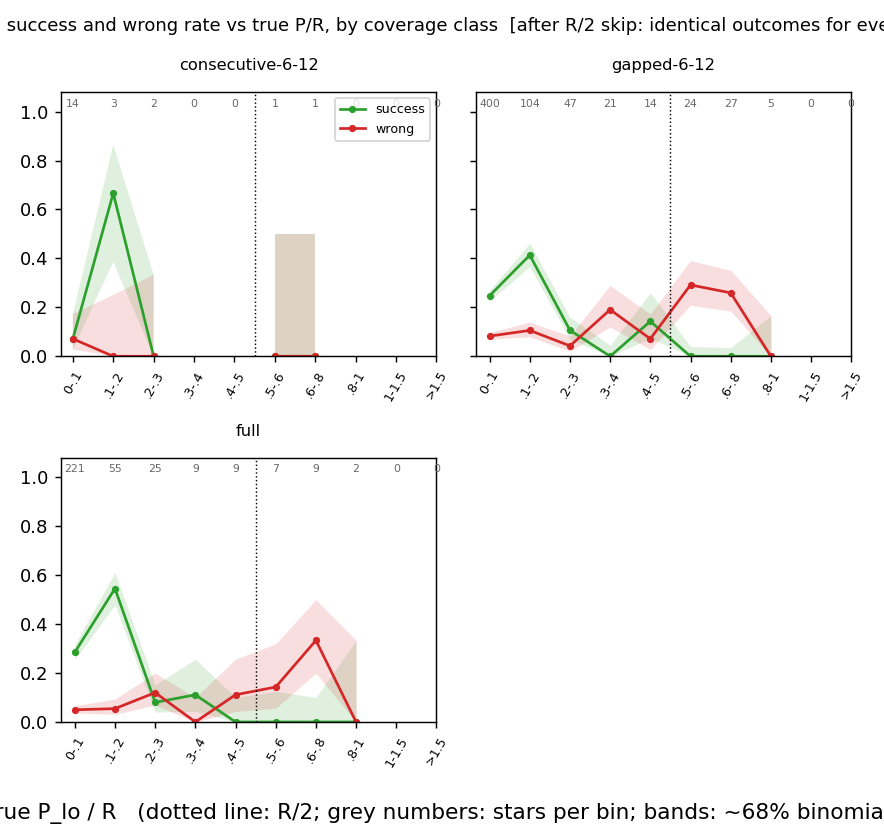

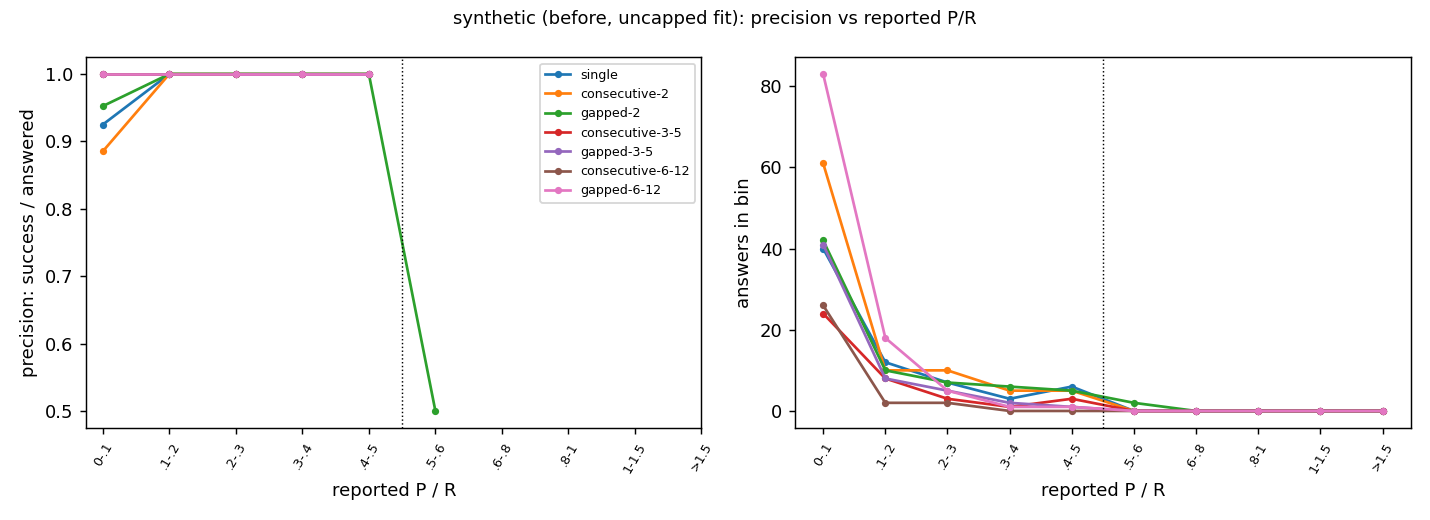

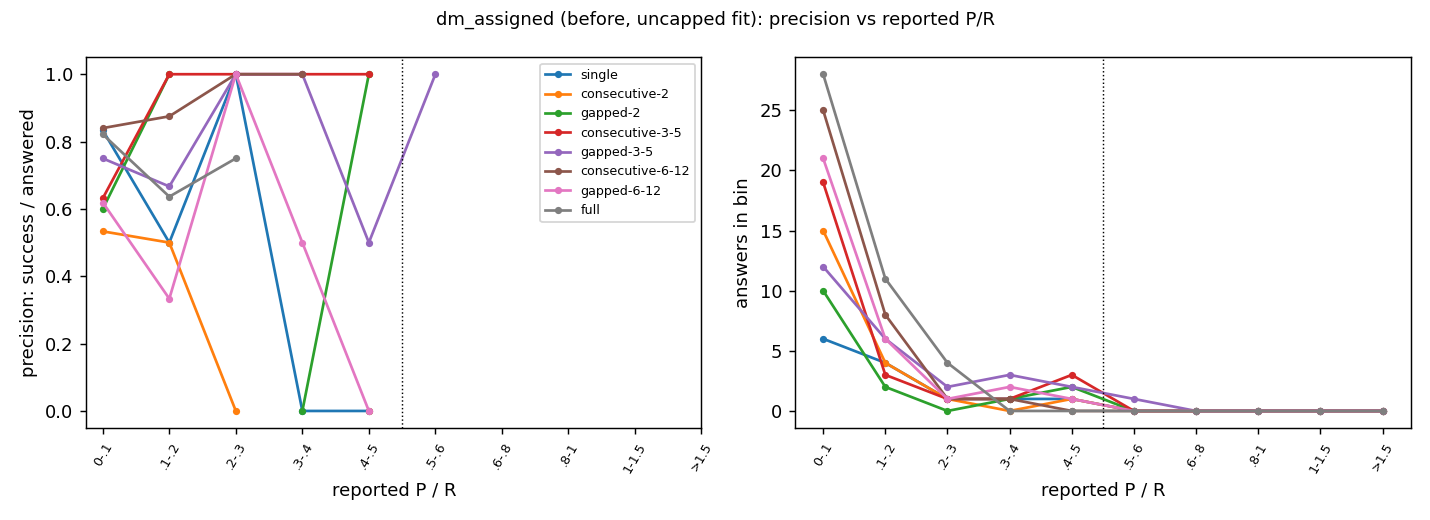

In [5]:
for f in ['truth_curve_synthetic', 'truth_curve_dm_assigned', 'truth_curve_dm_full', 'reported_precision_synthetic', 'reported_precision_dm_assigned']:
    display(Image(f'figures/{f}.png'))

## min_valid_frac 0.25 vs 0.3

,run,n,success_30,success_25,wrong_30,wrong_25,alias_30,alias_25,n_changed,gained_success,lost_success,new_wrong,fixed_wrong
0,dm_assigned,1000,0.148,0.148,0.054,0.059,0.009,0.010,14,2,2,8,3
1,syn_single,200,0.325,0.325,0.010,0.010,0.005,0.005,0,0,0,0,0
2,syn_consecutive-2,200,0.420,0.425,0.020,0.020,0.015,0.015,1,1,0,0,0
3,syn_gapped-2,200,0.345,0.345,0.010,0.005,0.005,0.005,4,2,2,0,1
4,dm_full,1000,0.248,0.251,0.088,0.092,0.014,0.015,23,8,5,5,1


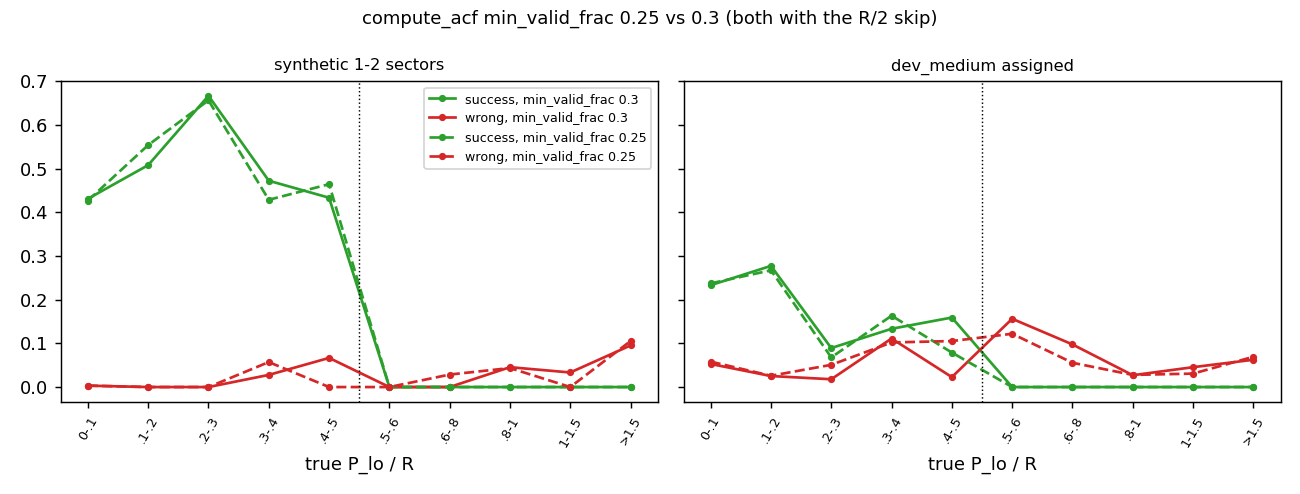

In [6]:
t = an.mvf_compare(); display(t.round(3))
display(Image('figures/mvf025_vs_030.png'))

## Per-method mechanisms
Pair-fraction curves (ACF reach), LS window sidelobes, per-method signatures by coverage class.

,pattern,longest_segment,R_030,R_025,R_over_longest,gain_025
0,single (1),26.395833,18.791667,20.062500,0.711918,0.067627
1,consecutive-2 (1-2),53.791667,36.562500,39.104167,0.679706,0.069516
2,gapped-2 (1-3),26.395833,18.770833,20.041667,0.711129,0.067703
3,gapped-2 (1-13),26.395833,18.770833,20.041667,0.711129,0.067703
4,gapped-3-5 (1-2-5),53.791667,28.937500,32.750000,0.537955,0.131749
5,full (1-13),355.187500,240.145833,258.666667,0.676110,0.077123


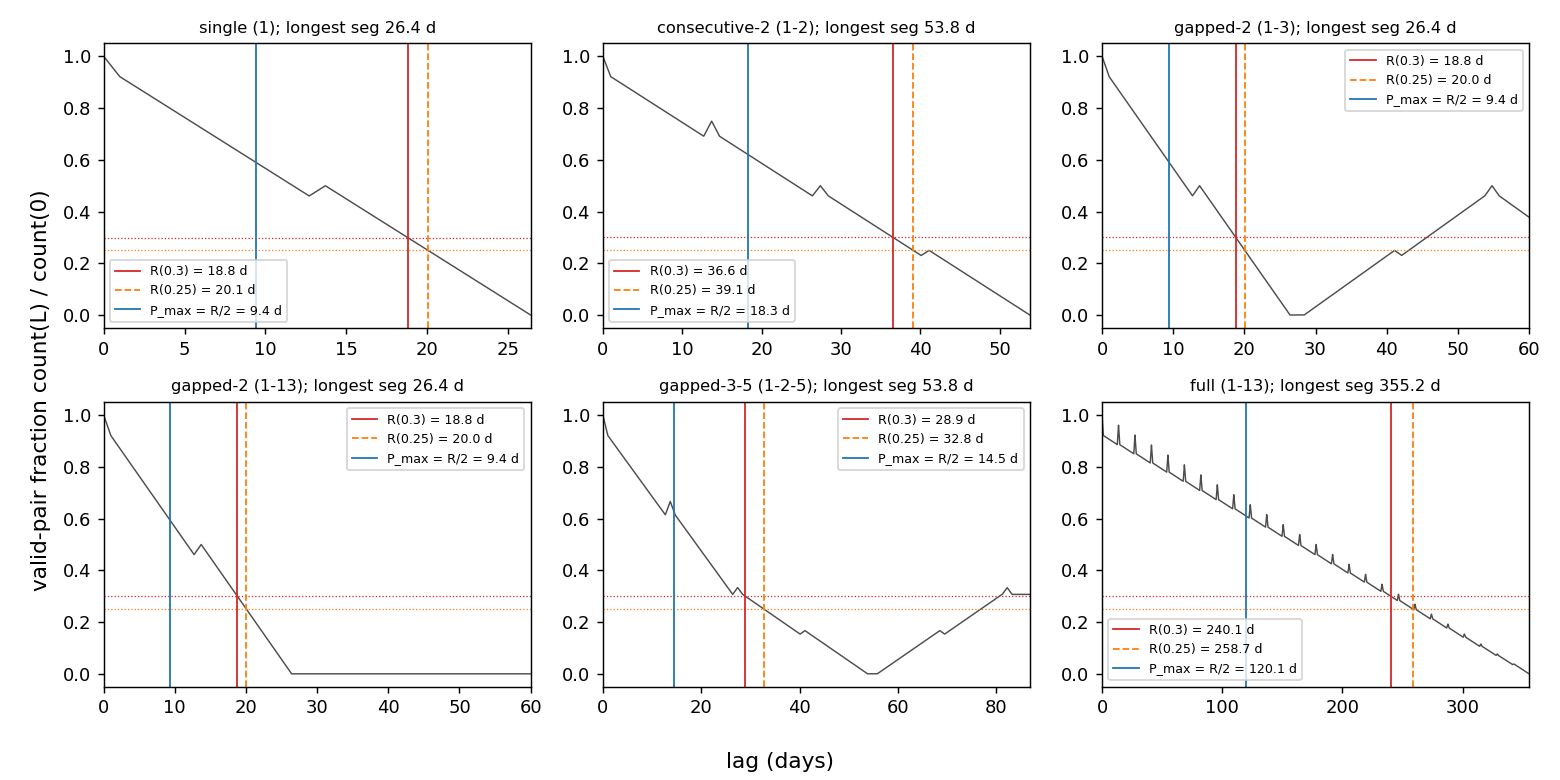

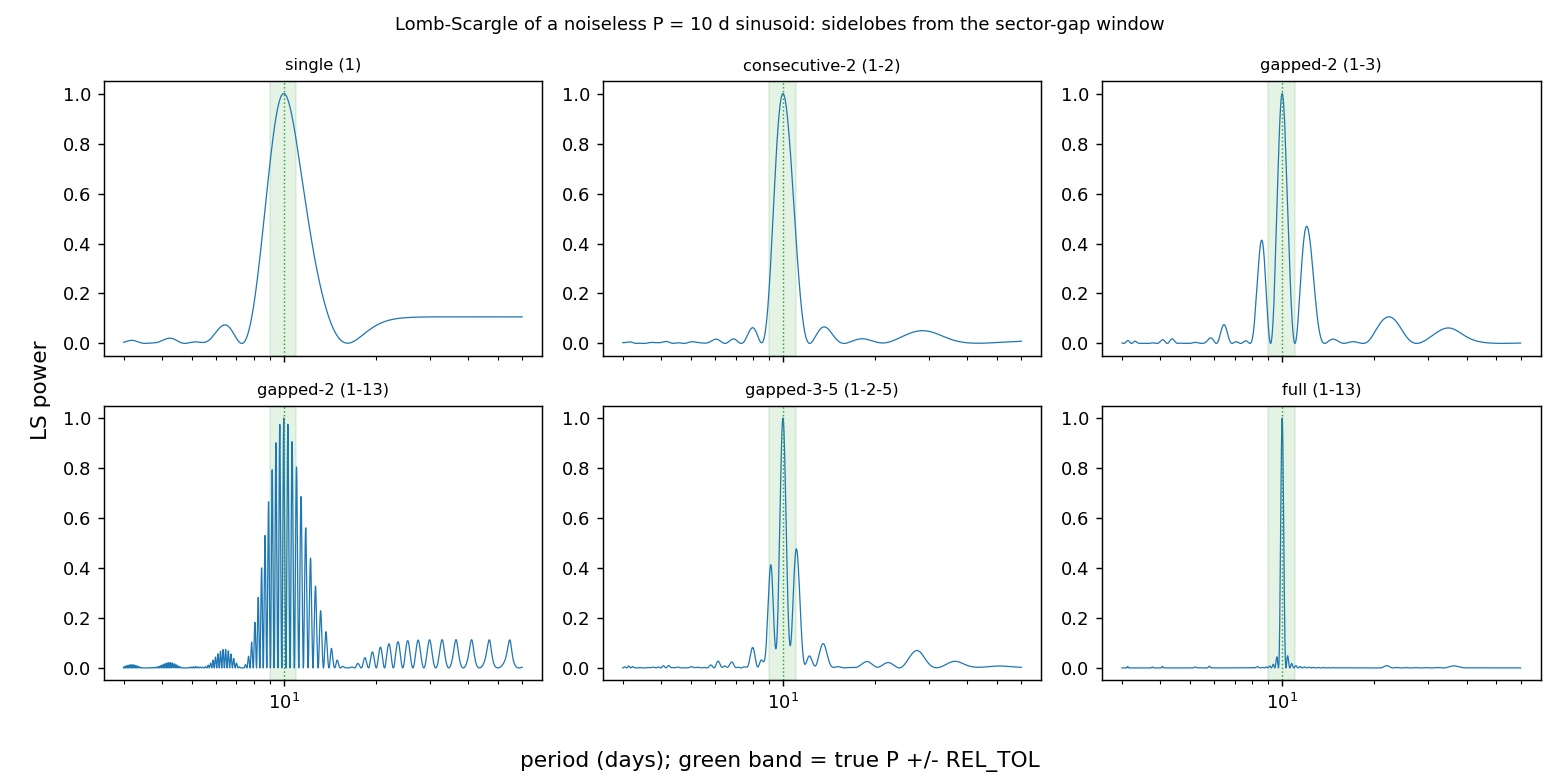

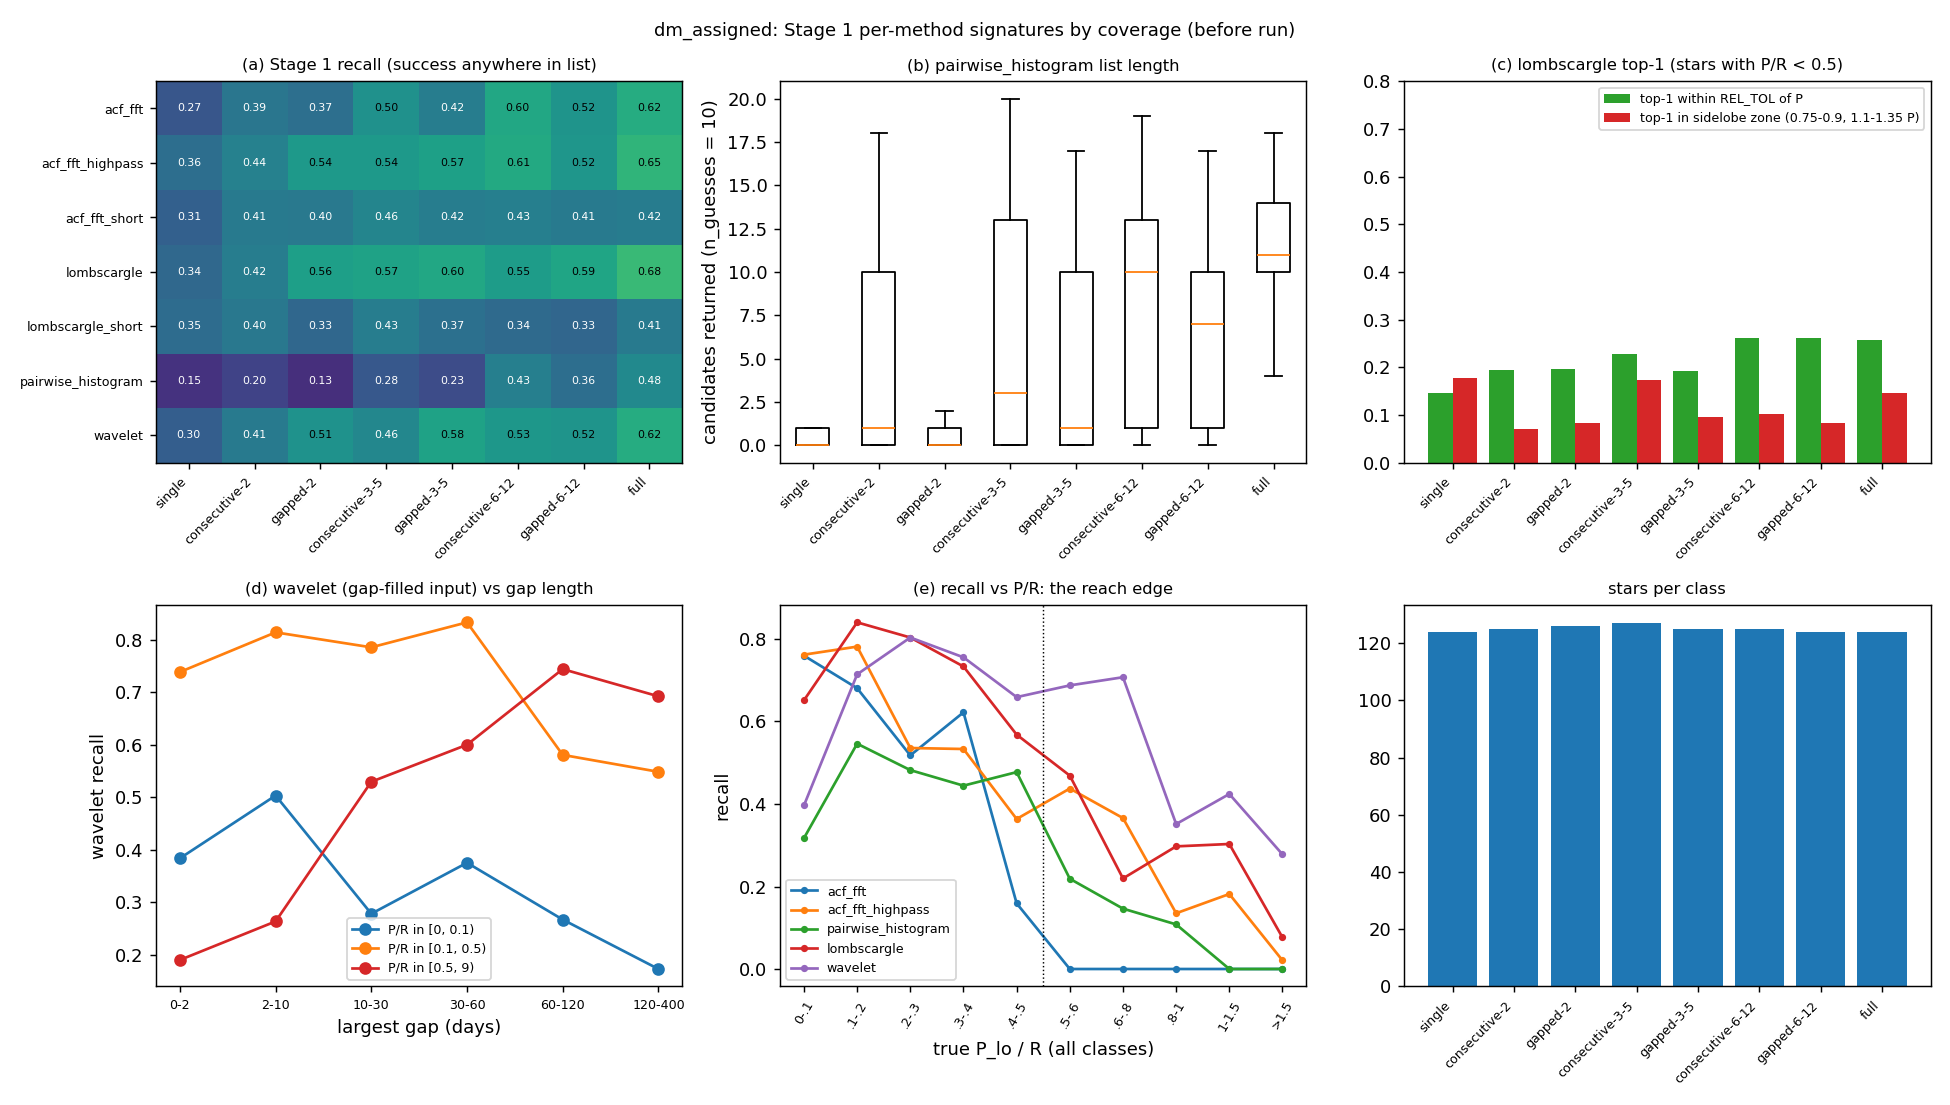

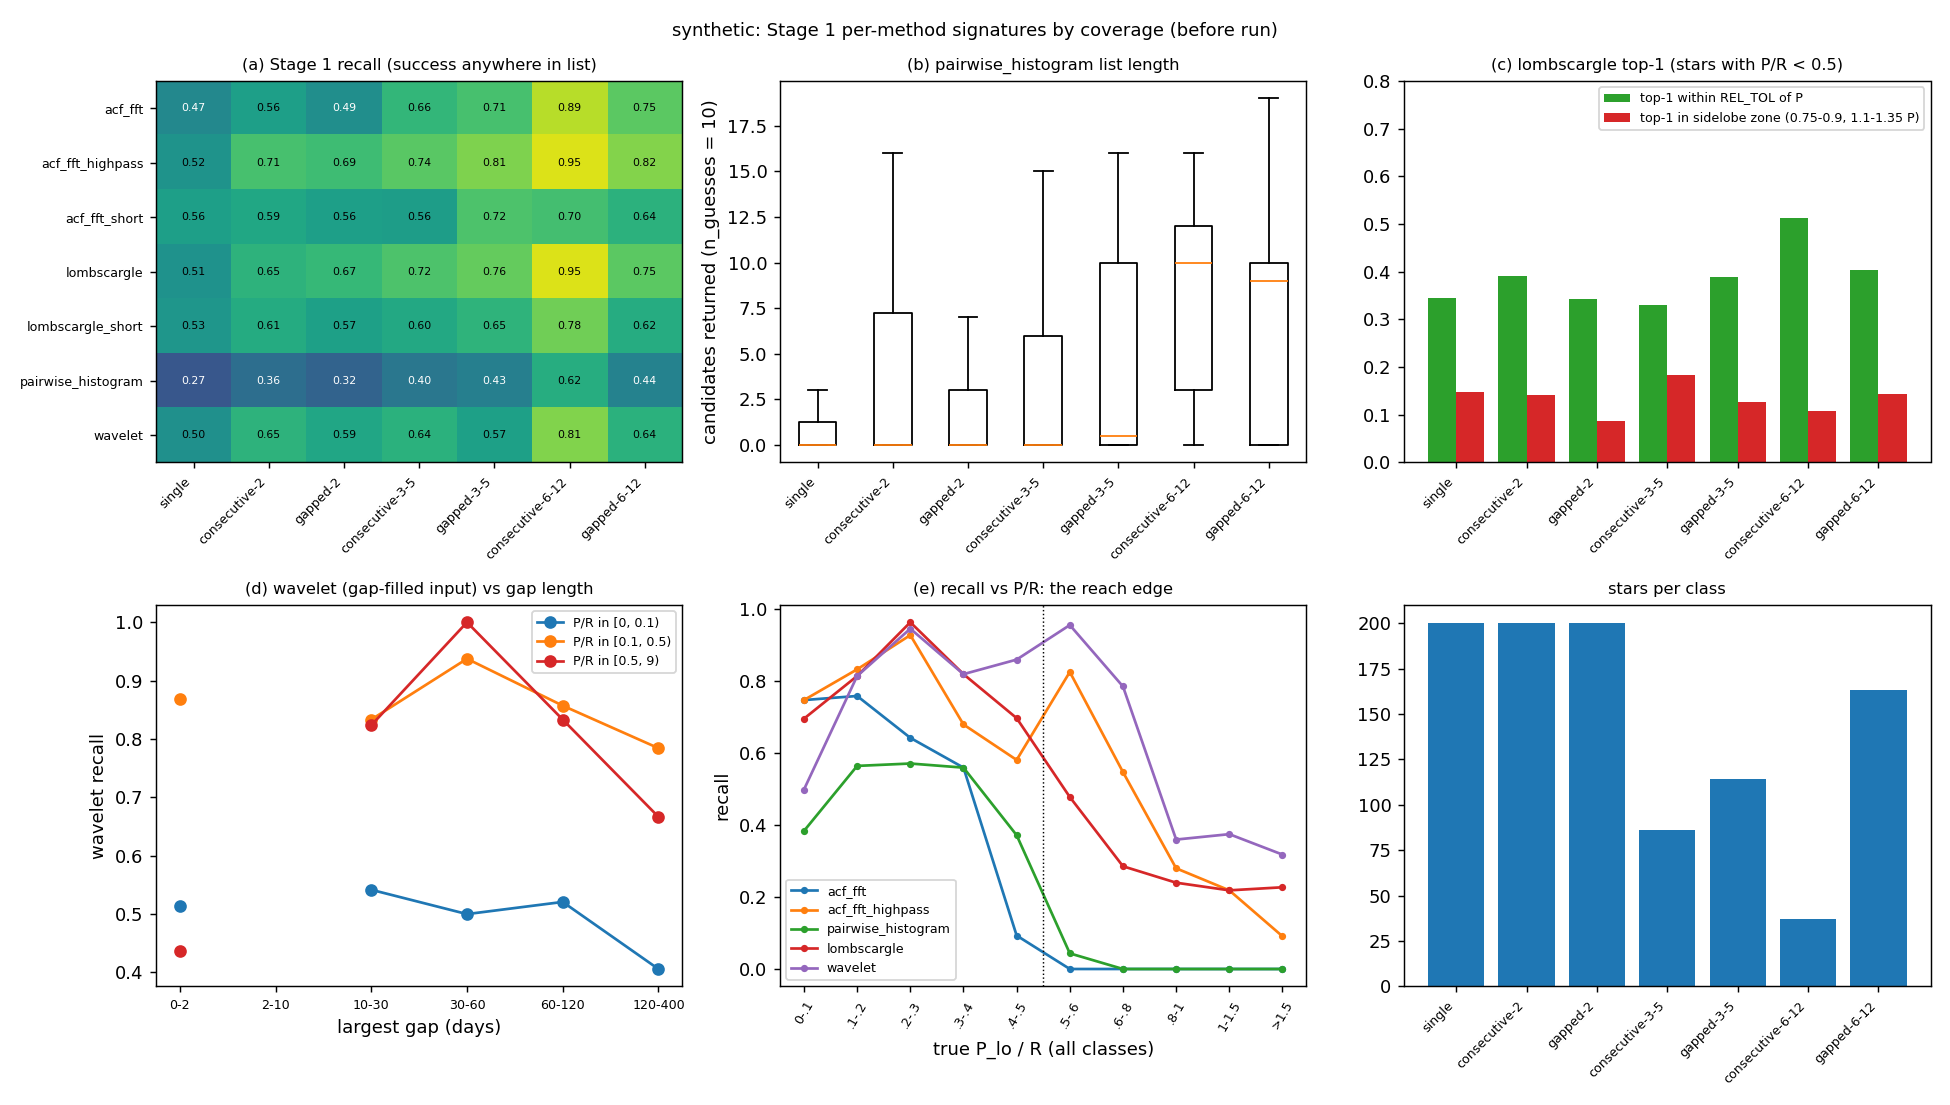

In [7]:
display(mech.pair_fraction_figure()); mech.ls_window_figure()
for lab, runs in (('dm_assigned', ('dm_assigned',)), ('synthetic', tuple(an.SYN))):
    mech.method_signatures(lab, runs)
for f in ['mech_pair_fraction', 'mech_ls_window', 'mech_methods_dm_assigned', 'mech_methods_synthetic']:
    display(Image(f'figures/{f}.png'))

## Example stars
Re-runs Stages 1-2 on six dev_medium stars (~30 s).

,case,star_id,coverage_class,true_period,R,truth_over_R,final_period,final_outcome
0,success near the limit (P/R 0.4-0.5),smarts-tess-v1.0-044671,gapped-2,8.1172,17.687500,0.426581,7.682319,correct
1,declined inside reach (P/R 0.3-0.5),smarts-tess-v1.0-026485,single,4.8331,15.104167,0.319985,NaN,none
2,wrong on an unsearchable star (P/R > 0.5),smarts-tess-v1.0-108023,consecutive-2,19.5300,36.083333,0.541247,0.172914,wrong
3,"unsearchable, correctly declined",smarts-tess-v1.0-082507,gapped-2,14.9045,16.375000,1.011532,NaN,none
4,pairwise_histogram: no candidates,smarts-tess-v1.0-000011,gapped-2,0.1030,20.041667,0.005139,NaN,none
5,gapped-2: reach = one sector,smarts-tess-v1.0-048739,gapped-2,8.8347,18.750000,0.581748,NaN,none


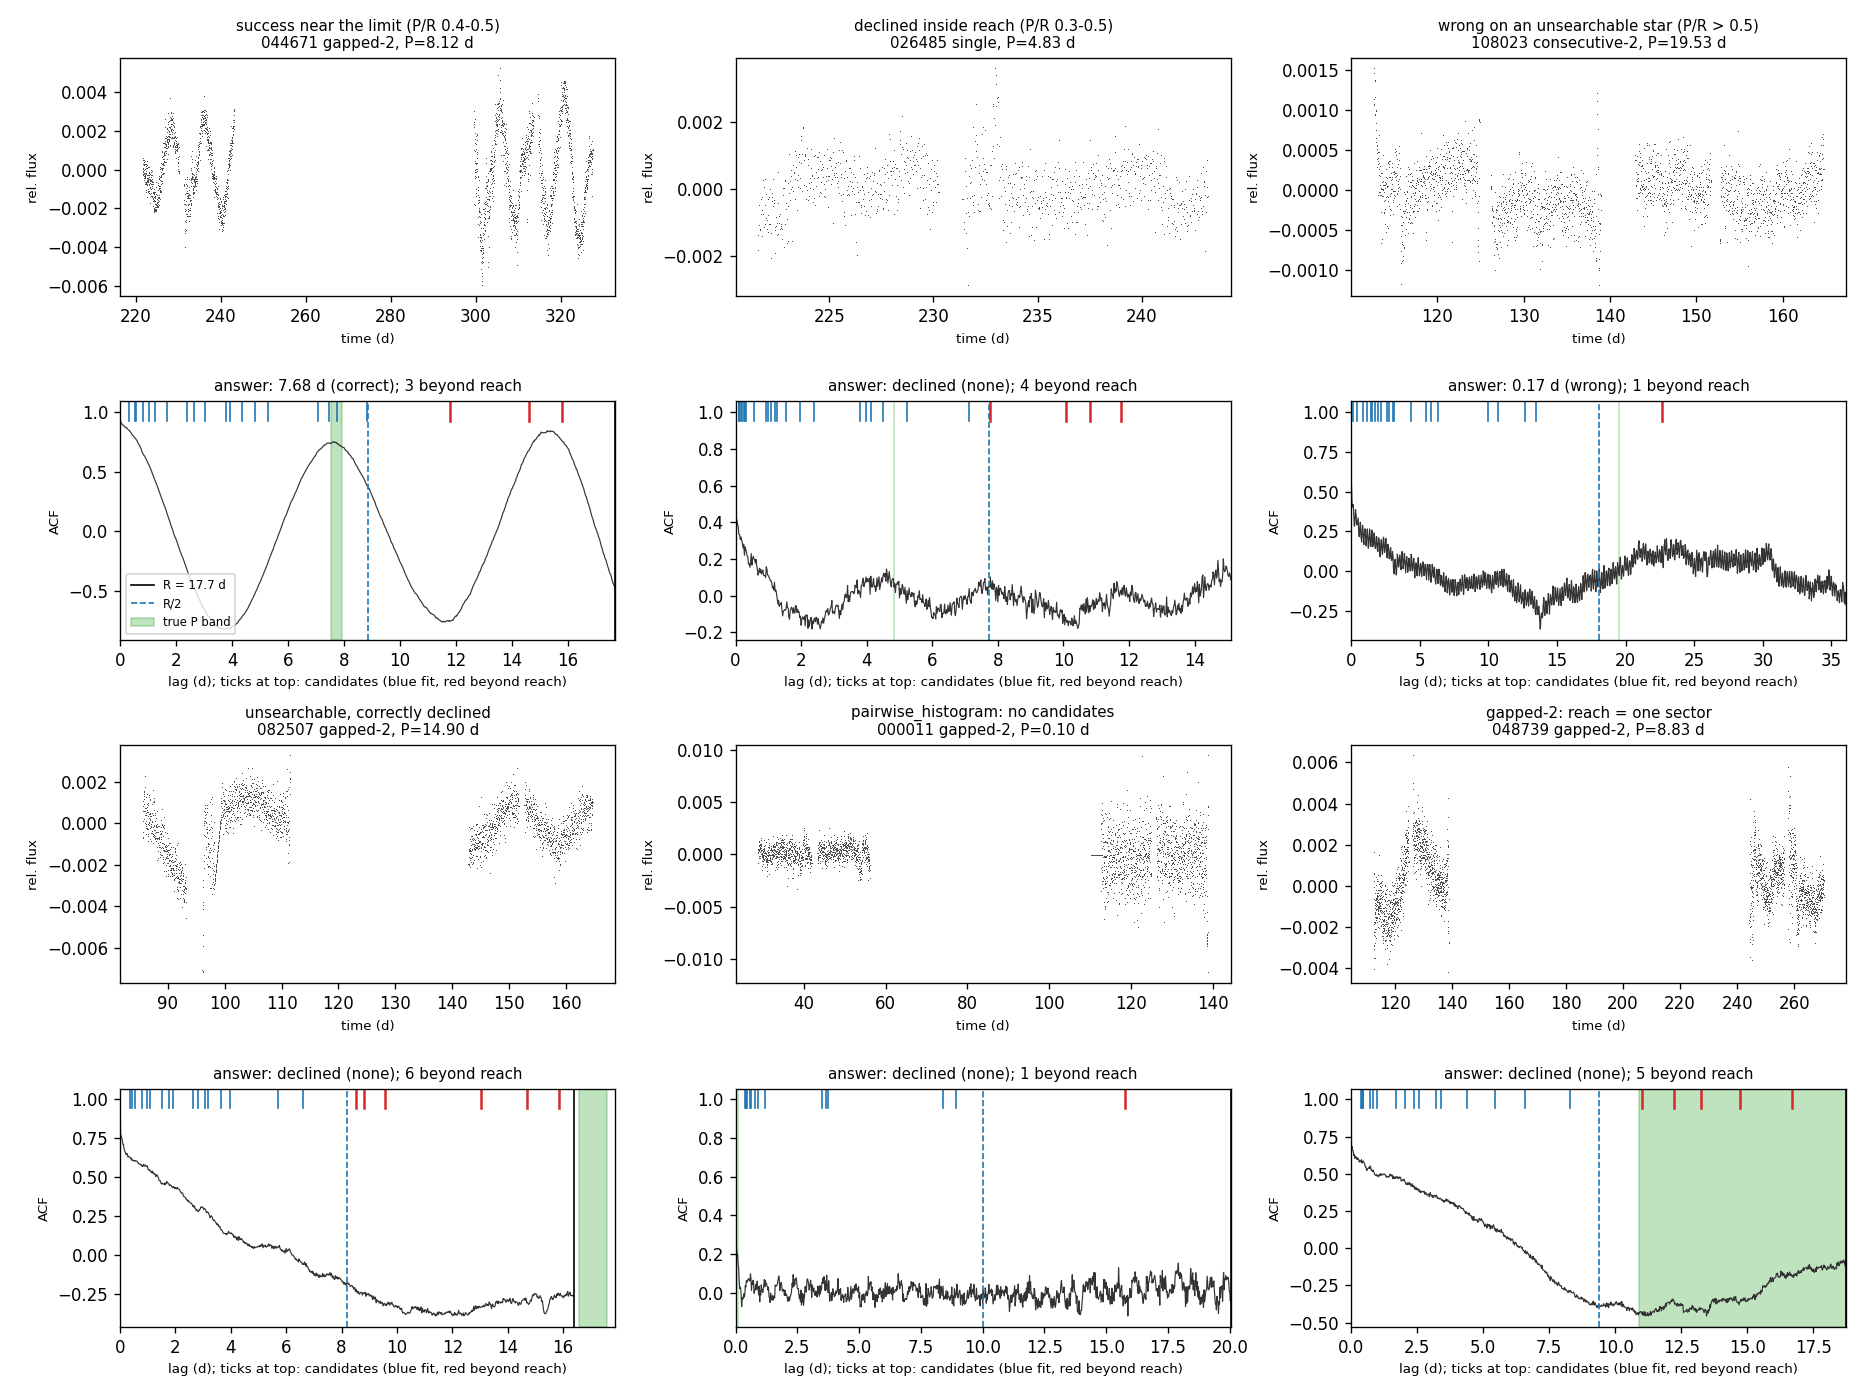

In [8]:
import examples
examples.main()
display(pd.read_csv('data/examples.csv'))
display(Image('figures/examples.png'))